In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
image_path = '/content/drive/MyDrive/path_to_your_image.jpg'

In [ ]:
import matplotlib.pyplot as plt
from google.colab import drive

In [ ]:
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


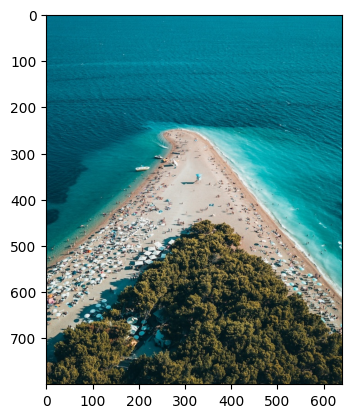

In [ ]:
img1=plt.imread('/content/drive/MyDrive/Colab Notebooks/Bản sao của Photo00003.jpg')
plt.imshow(img1)

In [ ]:
img_path = '/content/drive/MyDrive/Colab Notebooks/Bản sao của Photo00003.jpg'
img_ORG = plt.imread(img_path)

In [ ]:
img_ORG_R = img_ORG[:, :, 0]
img_ORG_G = img_ORG[:, :, 1]
img_ORG_B = img_ORG[:, :, 2]

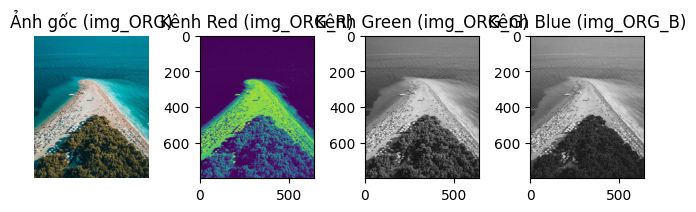

In [ ]:
plt.subplot(1, 4, 1)
plt.imshow(img_ORG)
plt.title('Ảnh gốc (img_ORG)')
plt.axis('off')


plt.subplot(1, 4, 2)
plt.imshow(img_ORG_R)
plt.title('Kênh Red (img_ORG_R)')



plt.subplot(1, 4, 3)
plt.imshow(img_ORG_G, cmap='gray')
plt.title('Kênh Green (img_ORG_G)')


plt.subplot(1, 4, 4)
plt.imshow(img_ORG_B, cmap='gray')
plt.title('Kênh Blue (img_ORG_B)')


plt.tight_layout()
plt.show()

In [ ]:
output1 = np.dstack((img_ORG_R, img_ORG_G, img_ORG_B))

In [ ]:
def XLA_linear(img, a=1, b=0):
  kq=img.astype('float32')
  kq=kq*a+b
  kq=kq.clip(0,255)
  return kq.astype('uint8')

In [ ]:
def XLA_to_grayscale(img):
  R = img_ORG[:, :, 0]
  G = img_ORG[:, :, 1]
  B = img_ORG[:, :, 2]
  return (R* 0.2989 + G*0.5870 +B*0.1140).clip(0, 255).astype('uint8')


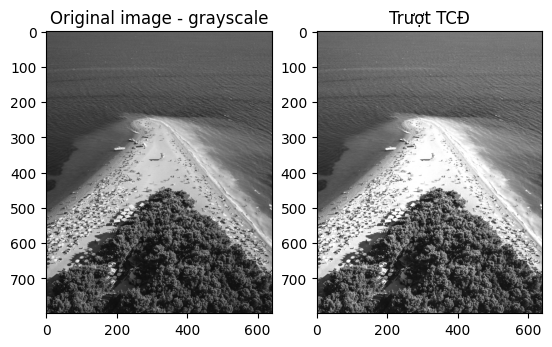

In [ ]:
plt.subplots(nrows = 1, ncols = 2)

plt.subplot(1, 2, 1)
plt.title('Original image - grayscale')
output2 = XLA_to_grayscale(img_ORG)
plt.imshow(output2, cmap='gray')

plt.subplot(1, 2, 2)
plt.title("Trượt TCĐ")
plt.imshow(XLA_linear(output2, 1, 50), cmap='gray')

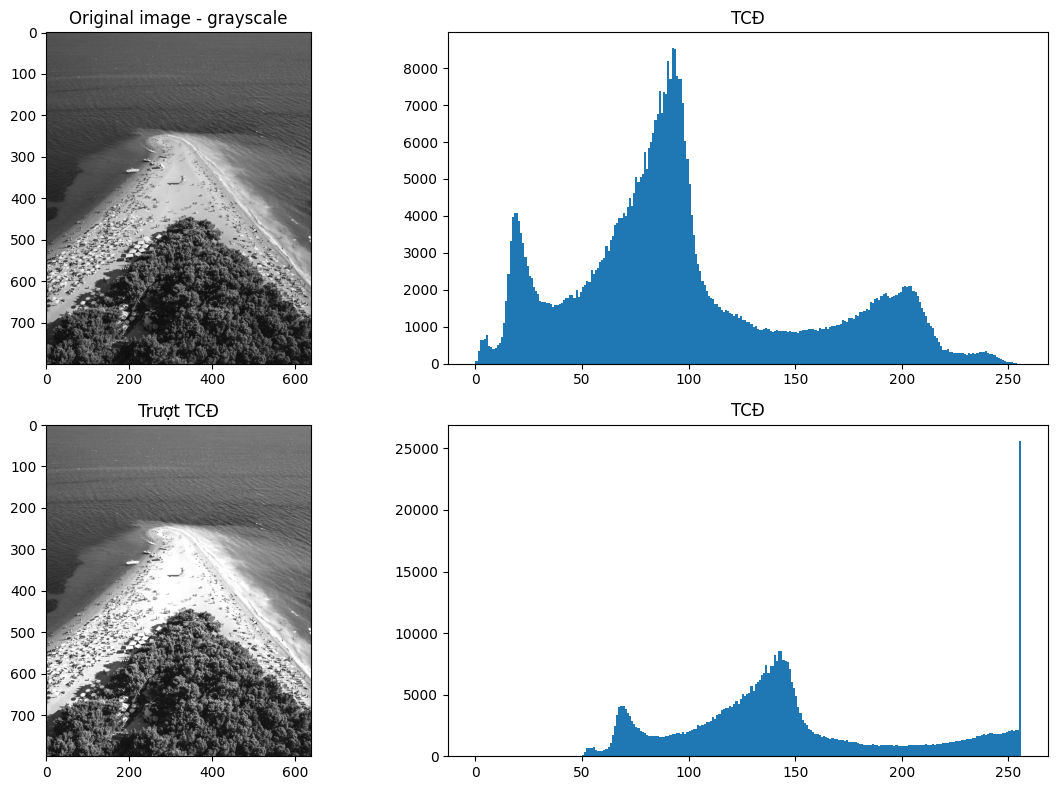

In [ ]:
plt.figure(figsize=(12, 8))



plt.subplot(2, 2, 1)
plt.title('Original image - grayscale')
output2 = XLA_to_grayscale(img_ORG)
plt.imshow(output2, cmap='gray')


plt.subplot(2, 2, 2)
plt.title('TCĐ')
plt.hist(output2.ravel(), bins=256, range=[0, 256])


output_truot = XLA_linear(output2, 1, 50)

plt.subplot(2, 2, 3)
plt.title('Trượt TCĐ')
plt.imshow(output_truot, cmap='gray')


plt.subplot(2, 2, 4)
plt.title('TCĐ')
plt.hist(output_truot.ravel(), bins=256, range=[0, 256])


plt.tight_layout()
plt.show()

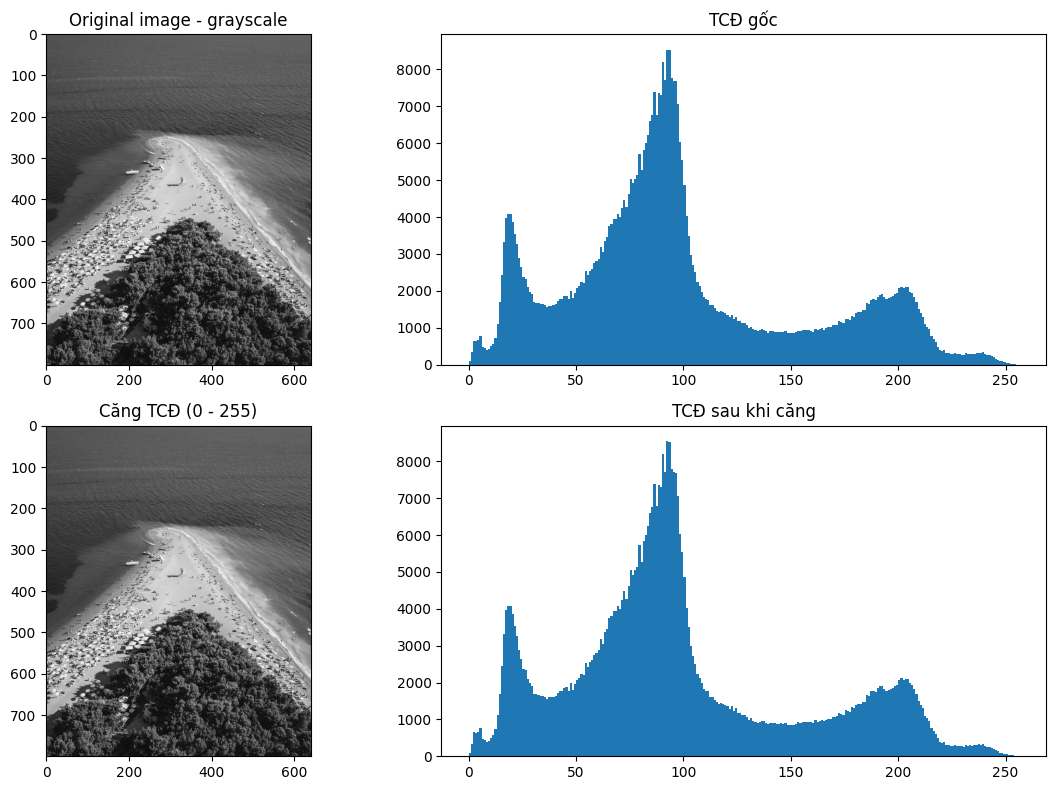

In [ ]:
import numpy as np
import matplotlib.pyplot as plt


output2 = XLA_to_grayscale(img_ORG)


i_min = np.min(output2)
i_max = np.max(output2)


output_cang = ((output2 - i_min) / (i_max - i_min) * 255).clip(0, 255).astype('uint8')


plt.figure(figsize=(12, 8))

#ảnh góc
plt.subplot(2, 2, 1)
plt.title('Original image - grayscale')
plt.imshow(output2, cmap='gray')

plt.subplot(2, 2, 2)
plt.title('TCĐ gốc')
plt.hist(output2.ravel(), bins=256, range=[0, 256])

#anh tcd ban dau
plt.subplot(2, 2, 3)
plt.title('Căng TCĐ (0 - 255)')
plt.imshow(output_cang, cmap='gray')
#ảnh tcd sau khi cang
plt.subplot(2, 2, 4)
plt.title('TCĐ sau khi căng')
plt.hist(output_cang.ravel(), bins=256, range=[0, 256])

plt.tight_layout()
plt.show()

In [ ]:
from scipy import signal
from skimage.filters import gaussian

<function matplotlib.pyplot.show(close=None, block=None)>

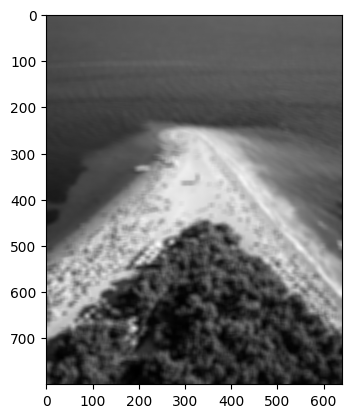

In [ ]:
kernel = np.ones((11, 11), np.float32) / 121
img3 = signal.convolve2d(output2, kernel, boundary='symm', mode='same')
plt.imshow(img3, cmap='gray')
plt.show